# Global Earthquakes in 2D & 3D on Vulkan GPU (`vkdata`)

End-to-end showcase of **2,116,537 real USGS global earthquakes** (`earthquakes-projected.parq`) across the entire **`vkdata`** stack:
- **`vkpandas` + `vknumpy`**: sub-second Parquet load & GPU feature engineering.
- **`vkplot` + `vkholoviews`**: 2D global seismic density over `CartoDark` + live cross-filtered Magnitude & Depth histograms.
- **`vkspatial` + `vkgeoviews`**: single-pass GPU `sjoin()` across 6 tectonic regions → interactive Choropleth + `vkpanel.DataTable`.
- **`vkshader.interact_3d`**: real-time **3D Vulkan GPU Subduction Zone Explorer** (`depth` up to 700 km along Japan/Mariana, Andes/Chile, Indonesia, Alaska, and California over a tilted Esri satellite map!).
- **`vklearn`**: GPU `KMeans` global seismic hotspot discovery.

In [1]:
import sys, time, urllib.request
from pathlib import Path

_root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import vknumpy as vnp
import vkpandas as vpd
import vkspatial as vksp
import vkshader as vks
import vkholoviews as hv
import vkgeoviews as gv
import vkpanel as pn
import vkplot.vkpandas  # registers .vkplot

data_path = Path.home() / ".cache/vkdata/earthquakes/earthquakes-projected.parq"
if not data_path.is_file():
    data_path.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading earthquakes-projected.parq (~142 MB)...")
    urllib.request.urlretrieve("https://datasets.holoviz.org/earthquakes/v1/earthquakes-projected.parq", data_path)

t0 = time.perf_counter()
df = vpd.read_parquet(data_path, columns=["easting", "northing", "longitude", "latitude", "depth", "mag"])
df = df[(df["depth"] >= 0.0) & (df["depth"] <= 700.0) & (df["mag"] > 0.0)]

# Discrete magnitude severity class for 3D color mode (0: <2, 1: 2-4, 2: 4-5.5, 3: >=5.5)
mag_np = df["mag"].to_numpy()
mag_cls = np.digitize(mag_np, bins=[2.0, 4.0, 5.5]).astype(np.int32)
df["mag_class"] = vnp.array(mag_cls, dtype=np.int32)

print(f"Loaded {len(df):,} global earthquakes into GPU vkpandas in {time.perf_counter() - t0:.2f}s")
print(f"Depth range: 0 .. {float(df['depth'].max()):.1f} km | Max Magnitude: M{float(df['mag'].max()):.1f}")

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


Loaded 1,912,231 global earthquakes into GPU vkpandas in 0.54s


[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


Depth range: 0 .. 700.0 km | Max Magnitude: M9.1


## 1. Global Seismic Density + Magnitude & Depth Distributions (`.vkplot`)

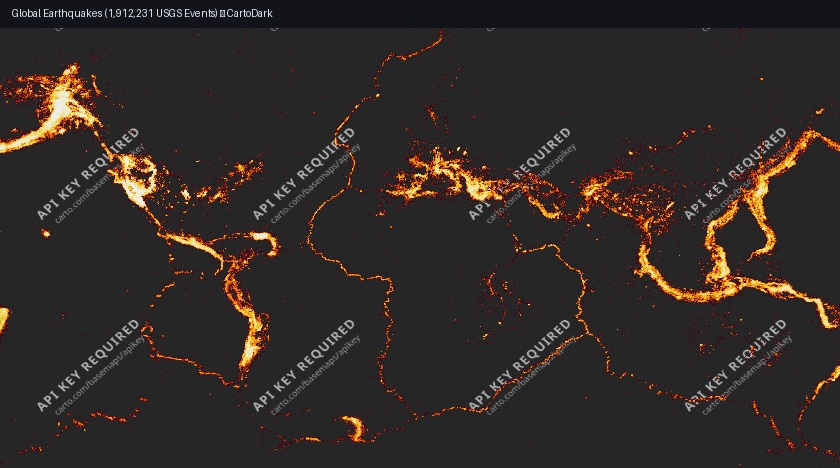

In [2]:
world_xr = (-19.5e6, 19.5e6)
world_yr = (-10.0e6, 13.0e6)

world_map = df.vkplot.points(
    "easting", "northing", tiles="carto_dark", how="eq_hist",
    width=840, height=440, xlim=world_xr, ylim=world_yr,
    title=f"Global Earthquakes ({len(df):,} USGS Events) — CartoDark",
)
mag_hist = df.vkplot.hist("mag", bins=45, range=(0, 8.5), width=415, height=240, title="Magnitude Distribution (M)")
dep_hist = df.vkplot.hist("depth", bins=45, range=(0, 300), width=415, height=240, title="Depth Distribution (0-300 km)")

world_map

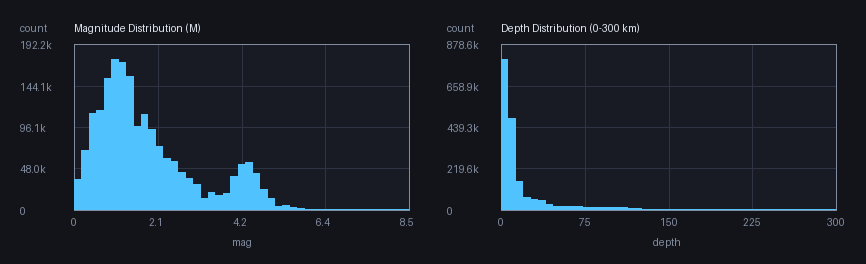

In [3]:
(mag_hist + dep_hist).cols(2)

## 2. Live Linked 2D Seismic Explorer (Pan/Zoom Updates Magnitude & Depth Histograms on GPU)

In [4]:
(
    df.vkplot.points("easting", "northing", tiles="carto_dark", width=620, height=420, xlim=world_xr, ylim=world_yr)
    + df.vkplot.hist("mag", bins=35, range=(0, 8.5), width=380, height=205, title="Viewport Magnitude (M)")
    + df.vkplot.hist("depth", bins=35, range=(0, 400), width=380, height=205, title="Viewport Depth (km)")
).interact();

## 3. Single-Pass GPU Tectonic Region Spatial Join (`vkspatial.sjoin` + `vkgeoviews.Polygons`)

In [5]:
# 6 major tectonic seismic regions defined in WGS84 (lon, lat)
SEISMIC_ZONES_LONLAT = {
    "Japan & Mariana":   [(128.0, 15.0), (150.0, 15.0), (150.0, 46.0), (128.0, 46.0)],
    "Andes / Chile":     [(-78.0, -45.0), (-64.0, -45.0), (-64.0, -5.0), (-78.0, -5.0)],
    "California / West": [(-128.0, 31.0), (-113.0, 31.0), (-113.0, 49.0), (-128.0, 49.0)],
    "Alaska / Aleutian": [(-175.0, 50.0), (-135.0, 50.0), (-135.0, 68.0), (-175.0, 68.0)],
    "Indonesia":         [(94.0, -12.0), (132.0, -12.0), (132.0, 8.0), (94.0, 8.0)],
    "Mediterranean":     [(-6.0, 33.0), (36.0, 33.0), (36.0, 46.0), (-6.0, 46.0)],
}

zones_merc = {}
for name, ring in SEISMIC_ZONES_LONLAT.items():
    mx, my = vksp.lonlat_to_mercator(np.array([p[0] for p in ring], dtype=np.float32), np.array([p[1] for p in ring], dtype=np.float32))
    zones_merc[name] = np.column_stack([mx.to_numpy(), my.to_numpy()]).astype(np.float32)

t0 = time.perf_counter()
gdf = vksp.GeoDataFrame(df, x="easting", y="northing", crs="EPSG:3857")
joined = gdf.sjoin(zones_merc, zone_col="zone_id", how="inner")
sjoin_ms = (time.perf_counter() - t0) * 1000.0

z_names = list(SEISMIC_ZONES_LONLAT.keys())
by_z_mean = joined.df[["zone_id", "depth", "mag"]].groupby("zone_id").mean()
by_z_cnt  = joined.df[["zone_id", "mag"]].groupby("zone_id").count()

mean_depth = {z_names[int(i)]: float(v) for i, v in zip(by_z_mean["zone_id"].to_list(), by_z_mean["depth"].to_list())}
cnt_map    = {z_names[int(i)]: int(v) for i, v in zip(by_z_cnt["zone_id"].to_list(), by_z_cnt["mag"].to_list())}
max_mag    = {z_names[i]: float(joined.df[joined.df["zone_id"] == i]["mag"].max()) for i in range(len(z_names)) if cnt_map.get(z_names[i], 0) > 0}

summary = {
    "Seismic Region": z_names,
    "Quakes": [f"{cnt_map.get(n, 0):,}" for n in z_names],
    "Mean Depth (km)": [round(mean_depth.get(n, 0.0), 1) for n in z_names],
    "Max Mag (M)": [round(max_mag.get(n, 0.0), 1) for n in z_names],
}
print(f"Single-pass GPU sjoin on {len(df):,} quakes -> {len(joined):,} matched in {sjoin_ms:.1f} ms")
pn.Card(pn.DataTable(summary, max_rows=10), title="Tectonic Zone Summary (Zero-Copy GPU sjoin)")

Single-pass GPU sjoin on 1,912,231 quakes -> 1,498,455 matched in 202.6 ms


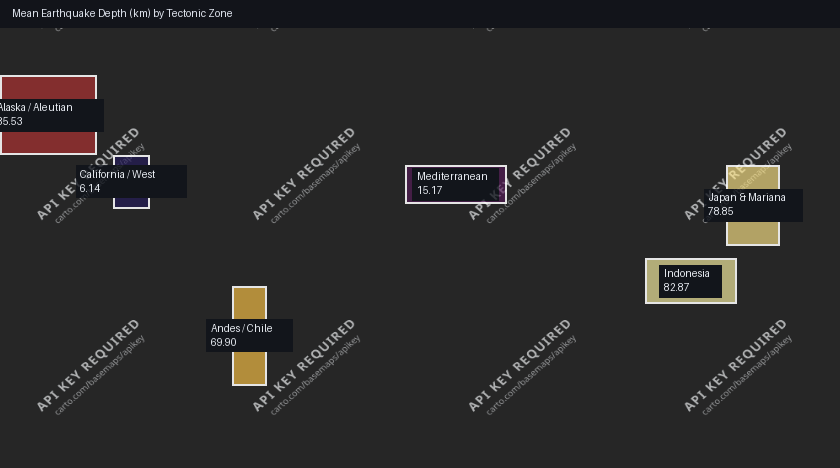

In [6]:
(
    gv.tile_sources.CartoDark
    * gv.Polygons(SEISMIC_ZONES_LONLAT, values=mean_depth, crs="EPSG:4326", alpha=165)
).opts(width=840, height=440, xlim=world_xr, ylim=world_yr, title="Mean Earthquake Depth (km) by Tectonic Zone")

## 4. Interactive 3D Vulkan GPU Subduction Zone Explorer (`vkshader.interact_3d`)

Uses **earthquake depth (0–650 km)** as the vertical 3D **Z** axis so you can literally see the **Wadati–Benioff tectonic subduction slabs** diving beneath **Japan & Mariana Trench**, **Andes / Chile**, and **Indonesia**!

- **Drag**: 3D Orbit (`yaw` / `pitch`)
- **Shift+Drag / Right-Drag**: Pan across the 3D map
- **Scroll wheel**: Zoom in/out
- **Double-click**: Reset camera

In [7]:
regions_3d = {}
for name, poly in zones_merc.items():
    regions_3d[name] = ((float(poly[:, 0].min()), float(poly[:, 0].max())), (float(poly[:, 1].min()), float(poly[:, 1].max())))
regions_3d["Full World"] = (world_xr, world_yr)

color_modes_3d = {
    "Depth (km, Fire)": (None, None),
    "Magnitude Class (Cyan <2, Yellow 2-4, Orange 4-5.5, Red 5.5+)": ("mag_class", ["cyan", "yellow", "orange", "red"]),
}

vks.interact_3d(
    df, "easting", "northing", "depth",
    width=840, height=540,
    z_range=(0.0, 650.0),
    kind="points",
    color_modes=color_modes_3d,
    regions=regions_3d,
    basemap="esri",
    z_scale=0.65,
);

## 5. GPU `vklearn.KMeans` — Global Seismic Hotspot Discovery

In [8]:
from vklearn import KMeans

# Cluster significant earthquakes (M >= 3.0) into 8 global tectonic hotspots on Vulkan GPU
sig = df[df["mag"] >= 3.0]
t0 = time.perf_counter()
km = KMeans(n_clusters=8, max_iter=20, random_state=42).fit(sig[["easting", "northing", "depth"]])
km_ms = (time.perf_counter() - t0) * 1000.0

centers = km.cluster_centers_.to_numpy()
clon, clat = vksp.mercator_to_lonlat(centers[:, 0], centers[:, 1])
labels = km.predict(sig[["easting", "northing", "depth"]])
counts = vnp.bincount(labels, minlength=8).to_numpy()

print(f"GPU KMeans (k=8) on {len(sig):,} M>=3.0 quakes finished in {km_ms:.1f} ms")
rows = {
    "Cluster": [f"#{i}" for i in range(8)],
    "Quakes (M>=3)": [f"{int(counts[i]):,}" for i in range(8)],
    "Center Lon": [round(float(clon.to_numpy()[i]), 2) for i in range(8)],
    "Center Lat": [round(float(clat.to_numpy()[i]), 2) for i in range(8)],
    "Mean Depth (km)": [round(float(centers[i, 2]), 1) for i in range(8)],
}
pn.Card(pn.DataTable(rows, max_rows=10), title="Global Seismic Hotspots Discovered by Vulkan GPU KMeans")

GPU KMeans (k=8) on 367,173 M>=3.0 quakes finished in 7032.7 ms
